# 🤖 Notebook 05: DistilBERT Fine-Tuning (The Star)
## AI-Generated Text Detection Project

**Goal:** Fine-tune DistilBERT — a lightweight transformer — for AI text detection. This is expected to be your best-performing model.

**Pipeline Position:** Step 5 of 7 (Data Exploration → Preprocessing → Classical → LSTM → **DistilBERT** → Evaluation → Explainability & Ethics)

---

### 🎯 What this notebook does:
1. Loads train/val/test splits
2. **Subsamples** the training data for speed (we don't need all 80K for BERT — 15K is plenty)
3. Tokenizes text with DistilBERT's tokenizer (handles casing, subwords automatically)
4. Fine-tunes `distilbert-base-uncased` for sequence classification
5. Evaluates with full metrics + cross-domain analysis
6. Saves the fine-tuned model + results

---

### 🤔 Why DistilBERT (not full BERT)?
- 40% smaller, 60% faster, retains 97% of BERT's performance
- Fits comfortably in T4 GPU memory
- Trains in ~15–25 min on Colab vs 1+ hour for full BERT
- Production-ready (used by many companies)

**Author:** [Your Name]  
**Date:** 2026

## ⚠️ IMPORTANT: Reset Runtime First

Before running this notebook, **reset the runtime** to free GPU memory from Notebook 04:
1. Runtime → Disconnect and delete runtime
2. Runtime → Change runtime type → T4 GPU → Save
3. Verify with the cell below

In [ ]:
!nvidia-smi

Fri May  1 18:45:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 📦 Step 1: Install & Import

In [ ]:
!pip install -q transformers datasets accelerate scikit-learn
print("✅ Packages installed")

✅ Packages installed


In [ ]:
import os
import json
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from time import time

import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")

✅ Device: cuda
   GPU: Tesla T4


## 💾 Step 2: Mount Drive & Load Data

We use `text_light` (minimally cleaned) since DistilBERT's tokenizer handles casing and punctuation.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = '/content/drive/MyDrive/ai-text-detection'
DATA_PATH = f'{PROJECT_PATH}/data'
MODELS_PATH = f'{PROJECT_PATH}/models'
RESULTS_PATH = f'{PROJECT_PATH}/results'
BERT_PATH = f'{MODELS_PATH}/distilbert_finetuned'
os.makedirs(BERT_PATH, exist_ok=True)

train_df = pd.read_csv(f'{DATA_PATH}/train.csv')
val_df = pd.read_csv(f'{DATA_PATH}/val.csv')
test_df = pd.read_csv(f'{DATA_PATH}/test.csv')

print(f"📊 Original sizes: Train={len(train_df):,}, Val={len(val_df):,}, Test={len(test_df):,}")

Mounted at /content/drive
📊 Original sizes: Train=52,443, Val=11,238, Test=11,238


## 🎯 Step 3: Subsample for Speed

**Decision:** We subsample to ~15K training samples to fit BERT training in 20–30 min on free Colab.

**Why this is fine:**
- BERT is pre-trained on billions of tokens — it doesn't need huge fine-tuning data
- 15K samples × stratified by domain + class = excellent coverage
- Test set stays at full size for fair evaluation

📝 **For your report:** Justify this decision. It's standard practice for transfer learning.

In [ ]:
from sklearn.model_selection import train_test_split

# Subsample train and val (stratified) — keep test full size
TRAIN_SUBSET_SIZE = 15000
VAL_SUBSET_SIZE = 3000

if len(train_df) > TRAIN_SUBSET_SIZE:
    train_df['stratify_key'] = train_df['label'].astype(str) + '_' + train_df['domain']
    train_df_small, _ = train_test_split(
        train_df, train_size=TRAIN_SUBSET_SIZE,
        stratify=train_df['stratify_key'], random_state=SEED
    )
    train_df_small = train_df_small.drop(columns='stratify_key').reset_index(drop=True)
else:
    train_df_small = train_df.copy()

if len(val_df) > VAL_SUBSET_SIZE:
    val_df['stratify_key'] = val_df['label'].astype(str) + '_' + val_df['domain']
    val_df_small, _ = train_test_split(
        val_df, train_size=VAL_SUBSET_SIZE,
        stratify=val_df['stratify_key'], random_state=SEED
    )
    val_df_small = val_df_small.drop(columns='stratify_key').reset_index(drop=True)
else:
    val_df_small = val_df.copy()

print(f"📊 Subsampled sizes: Train={len(train_df_small):,}, Val={len(val_df_small):,}, Test={len(test_df):,}")
print(f"📊 Train class balance: {train_df_small['label'].value_counts().to_dict()}")

📊 Subsampled sizes: Train=15,000, Val=3,000, Test=11,238
📊 Train class balance: {0: 9760, 1: 5240}


## 🔤 Step 4: Tokenize Text with DistilBERT Tokenizer

DistilBERT uses **WordPiece tokenization** — it splits words into subword pieces, handling out-of-vocabulary words gracefully.

**Configuration:**
- `MAX_LEN = 256` — DistilBERT's max is 512, but 256 is faster and sufficient for most texts

In [ ]:
MODEL_NAME = 'distilbert-base-uncased'
MAX_LEN = 256

print("📥 Loading DistilBERT tokenizer...")
tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)
print("✅ Tokenizer ready")

# Quick demo
sample = "This is a sample text to demonstrate DistilBERT tokenization!"
encoded = tokenizer(sample, padding='max_length', truncation=True, max_length=MAX_LEN, return_tensors='pt')
print(f"\n🔍 Demo tokenization:")
print(f"   Original: {sample}")
print(f"   Token IDs (first 15): {encoded['input_ids'][0][:15].tolist()}")
print(f"   Decoded tokens: {tokenizer.convert_ids_to_tokens(encoded['input_ids'][0][:15])}")

📥 Loading DistilBERT tokenizer...


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

✅ Tokenizer ready

🔍 Demo tokenization:
   Original: This is a sample text to demonstrate DistilBERT tokenization!
   Token IDs (first 15): [101, 2023, 2003, 1037, 7099, 3793, 2000, 10580, 4487, 16643, 23373, 19204, 3989, 999, 102]
   Decoded tokens: ['[CLS]', 'this', 'is', 'a', 'sample', 'text', 'to', 'demonstrate', 'di', '##sti', '##lbert', 'token', '##ization', '!', '[SEP]']


## 🗂️ Step 5: Build PyTorch Dataset Class

We define a custom Dataset to feed DistilBERT during training.

In [ ]:
class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = int(self.labels[idx])

        encoding = self.tokenizer(
            text,
            padding='max_length',
            truncation=True,
            max_length=self.max_len,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(label, dtype=torch.long)
        }

# Use text_light for transformers
train_ds = TextDataset(train_df_small['text_light'].fillna('').values, train_df_small['label'].values, tokenizer, MAX_LEN)
val_ds   = TextDataset(val_df_small['text_light'].fillna('').values,   val_df_small['label'].values,   tokenizer, MAX_LEN)
test_ds  = TextDataset(test_df['text_light'].fillna('').values,        test_df['label'].values,        tokenizer, MAX_LEN)

BATCH_SIZE = 16
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE*2, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE*2, shuffle=False, num_workers=2)

print(f"✅ Datasets ready:")
print(f"   Train batches: {len(train_loader)}")
print(f"   Val batches:   {len(val_loader)}")
print(f"   Test batches:  {len(test_loader)}")

✅ Datasets ready:
   Train batches: 938
   Val batches:   94
   Test batches:  352


## 🏗️ Step 6: Load Pre-Trained DistilBERT for Classification

In [ ]:
print("📥 Loading DistilBERT for sequence classification...")
model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2  # Binary: Human vs AI
).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\n📊 Model: {MODEL_NAME}")
print(f"📊 Total parameters: {total_params:,}")
print(f"📊 Trainable parameters: {trainable_params:,}")

📥 Loading DistilBERT for sequence classification...


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



📊 Model: distilbert-base-uncased
📊 Total parameters: 66,955,010
📊 Trainable parameters: 66,955,010


## ⚙️ Step 7: Set Up Optimizer & Scheduler

**Standard transformer fine-tuning recipe:**
- AdamW optimizer (Adam with weight decay)
- Learning rate: 2e-5 (much smaller than training-from-scratch)
- Linear schedule with warmup (gradually ramps up LR, then decays)
- 3 epochs (more risks overfitting on 15K samples)

In [ ]:
EPOCHS = 3
LR = 2e-5
WARMUP_RATIO = 0.1

optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps
)

print(f"✅ Optimizer + scheduler ready")
print(f"   Epochs: {EPOCHS}")
print(f"   Learning rate: {LR}")
print(f"   Total steps: {total_steps}")
print(f"   Warmup steps: {warmup_steps}")

✅ Optimizer + scheduler ready
   Epochs: 3
   Learning rate: 2e-05
   Total steps: 2814
   Warmup steps: 281


## 🚂 Step 8: Training Loop

Custom training loop (more transparent than `Trainer` API). We track loss + accuracy each epoch and save the best model.

⏱️ Expected: 6–10 min per epoch × 3 epochs = ~20–30 min total.

In [ ]:
def evaluate(model, loader, device):
    """Run model on a loader and return (avg_loss, accuracy, all_preds, all_probs)."""
    model.eval()
    losses, all_preds, all_labels, all_probs = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            losses.append(outputs.loss.item())
            probs = torch.softmax(outputs.logits, dim=1)[:, 1].cpu().numpy()
            preds = outputs.logits.argmax(dim=1).cpu().numpy()
            all_probs.extend(probs)
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())
    return np.mean(losses), accuracy_score(all_labels, all_preds), np.array(all_preds), np.array(all_probs), np.array(all_labels)

history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_val_f1 = 0

print(f"🚂 Starting fine-tuning ({EPOCHS} epochs)...\n")
t_total = time()

for epoch in range(EPOCHS):
    model.train()
    epoch_losses = []
    t_epoch = time()

    for step, batch in enumerate(train_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        epoch_losses.append(loss.item())

        if (step + 1) % 100 == 0:
            print(f"  Epoch {epoch+1} | Step {step+1}/{len(train_loader)} | Loss: {np.mean(epoch_losses[-100:]):.4f}")

    train_loss = np.mean(epoch_losses)
    val_loss, val_acc, val_preds, val_probs, val_labels = evaluate(model, val_loader, device)
    val_f1 = f1_score(val_labels, val_preds)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)

    print(f"\n✅ Epoch {epoch+1} done in {(time()-t_epoch)/60:.1f} min")
    print(f"   Train Loss: {train_loss:.4f}")
    print(f"   Val Loss:   {val_loss:.4f}")
    print(f"   Val Acc:    {val_acc:.4f}")
    print(f"   Val F1:     {val_f1:.4f}\n")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        model.save_pretrained(BERT_PATH)
        tokenizer.save_pretrained(BERT_PATH)
        print(f"   💾 New best model saved (val F1 = {val_f1:.4f})\n")

print(f"\n🎉 Training complete in {(time()-t_total)/60:.1f} min total")
print(f"🏆 Best Val F1: {best_val_f1:.4f}")

🚂 Starting fine-tuning (3 epochs)...

  Epoch 1 | Step 100/938 | Loss: 0.6212
  Epoch 1 | Step 200/938 | Loss: 0.1877
  Epoch 1 | Step 300/938 | Loss: 0.0966
  Epoch 1 | Step 400/938 | Loss: 0.0415
  Epoch 1 | Step 500/938 | Loss: 0.0413
  Epoch 1 | Step 600/938 | Loss: 0.0477
  Epoch 1 | Step 700/938 | Loss: 0.0738
  Epoch 1 | Step 800/938 | Loss: 0.0342
  Epoch 1 | Step 900/938 | Loss: 0.0572

✅ Epoch 1 done in 5.8 min
   Train Loss: 0.1296
   Val Loss:   0.0587
   Val Acc:    0.9863
   Val F1:     0.9808



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   💾 New best model saved (val F1 = 0.9808)

  Epoch 2 | Step 100/938 | Loss: 0.0177
  Epoch 2 | Step 200/938 | Loss: 0.0102
  Epoch 2 | Step 300/938 | Loss: 0.0136
  Epoch 2 | Step 400/938 | Loss: 0.0211
  Epoch 2 | Step 500/938 | Loss: 0.0075
  Epoch 2 | Step 600/938 | Loss: 0.0035
  Epoch 2 | Step 700/938 | Loss: 0.0128
  Epoch 2 | Step 800/938 | Loss: 0.0109
  Epoch 2 | Step 900/938 | Loss: 0.0179

✅ Epoch 2 done in 5.9 min
   Train Loss: 0.0134
   Val Loss:   0.0654
   Val Acc:    0.9877
   Val F1:     0.9826



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   💾 New best model saved (val F1 = 0.9826)

  Epoch 3 | Step 100/938 | Loss: 0.0042
  Epoch 3 | Step 200/938 | Loss: 0.0014
  Epoch 3 | Step 300/938 | Loss: 0.0044
  Epoch 3 | Step 400/938 | Loss: 0.0001
  Epoch 3 | Step 500/938 | Loss: 0.0002
  Epoch 3 | Step 600/938 | Loss: 0.0045
  Epoch 3 | Step 700/938 | Loss: 0.0027
  Epoch 3 | Step 800/938 | Loss: 0.0007
  Epoch 3 | Step 900/938 | Loss: 0.0076

✅ Epoch 3 done in 5.9 min
   Train Loss: 0.0028
   Val Loss:   0.0658
   Val Acc:    0.9887
   Val F1:     0.9840



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   💾 New best model saved (val F1 = 0.9840)


🎉 Training complete in 17.7 min total
🏆 Best Val F1: 0.9840


## 📈 Step 9: Plot Training History

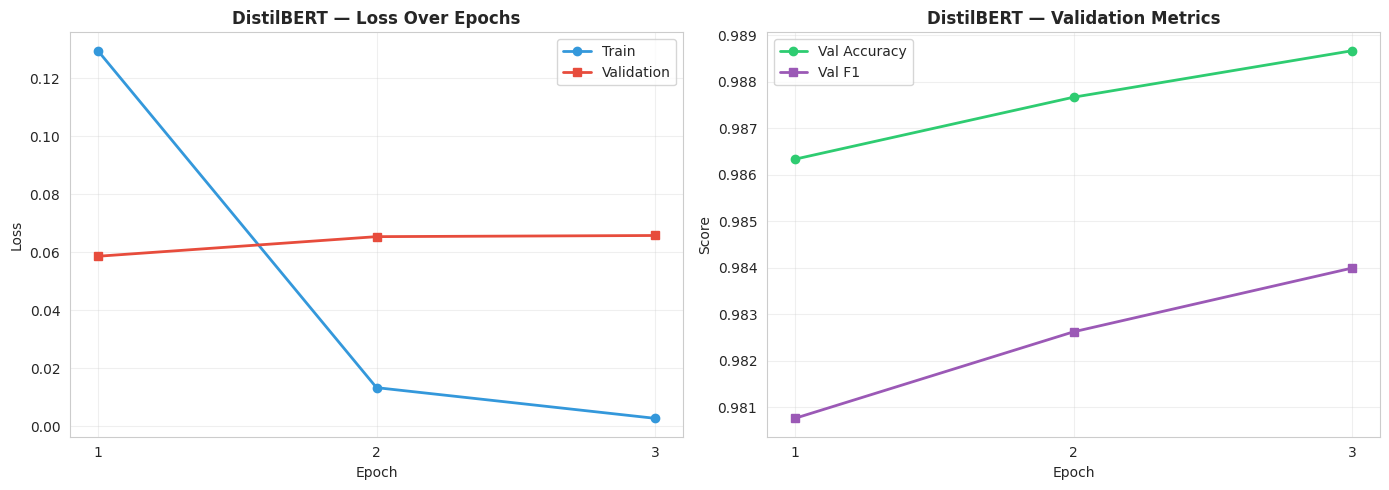

💾 Training history saved


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_axis = range(1, EPOCHS + 1)

axes[0].plot(epochs_axis, history['train_loss'], 'o-', label='Train', color='#3498db', linewidth=2)
axes[0].plot(epochs_axis, history['val_loss'],   's-', label='Validation', color='#e74c3c', linewidth=2)
axes[0].set_title('DistilBERT — Loss Over Epochs', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xticks(epochs_axis)

axes[1].plot(epochs_axis, history['val_acc'], 'o-', label='Val Accuracy', color='#2ecc71', linewidth=2)
axes[1].plot(epochs_axis, history['val_f1'],  's-', label='Val F1', color='#9b59b6', linewidth=2)
axes[1].set_title('DistilBERT — Validation Metrics', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xticks(epochs_axis)

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/distilbert_training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Training history saved")

## 🧪 Step 10: Evaluate on Test Set

Load the best checkpoint and run final evaluation.

In [ ]:
# Reload the BEST checkpoint (in case last epoch wasn't best)
print("📥 Loading best checkpoint...")
model = DistilBertForSequenceClassification.from_pretrained(BERT_PATH).to(device)

print("🧪 Evaluating on test set (full size)...")
test_loss, test_acc, y_pred, y_proba, y_true = evaluate(model, test_loader, device)

bert_metrics = {
    'model':     'DistilBERT',
    'accuracy':  accuracy_score(y_true, y_pred),
    'precision': precision_score(y_true, y_pred),
    'recall':    recall_score(y_true, y_pred),
    'f1':        f1_score(y_true, y_pred),
    'roc_auc':   roc_auc_score(y_true, y_proba)
}

print(f"\n📊 DistilBERT Test Metrics:")
print(f"   Accuracy:  {bert_metrics['accuracy']:.4f}")
print(f"   Precision: {bert_metrics['precision']:.4f}")
print(f"   Recall:    {bert_metrics['recall']:.4f}")
print(f"   F1-score:  {bert_metrics['f1']:.4f}")
print(f"   ROC AUC:   {bert_metrics['roc_auc']:.4f}")

📥 Loading best checkpoint...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

🧪 Evaluating on test set (full size)...

📊 DistilBERT Test Metrics:
   Accuracy:  0.9891
   Precision: 0.9706
   Recall:    0.9992
   F1-score:  0.9847
   ROC AUC:   0.9998


## 📊 Step 11: Confusion Matrix + ROC Curve

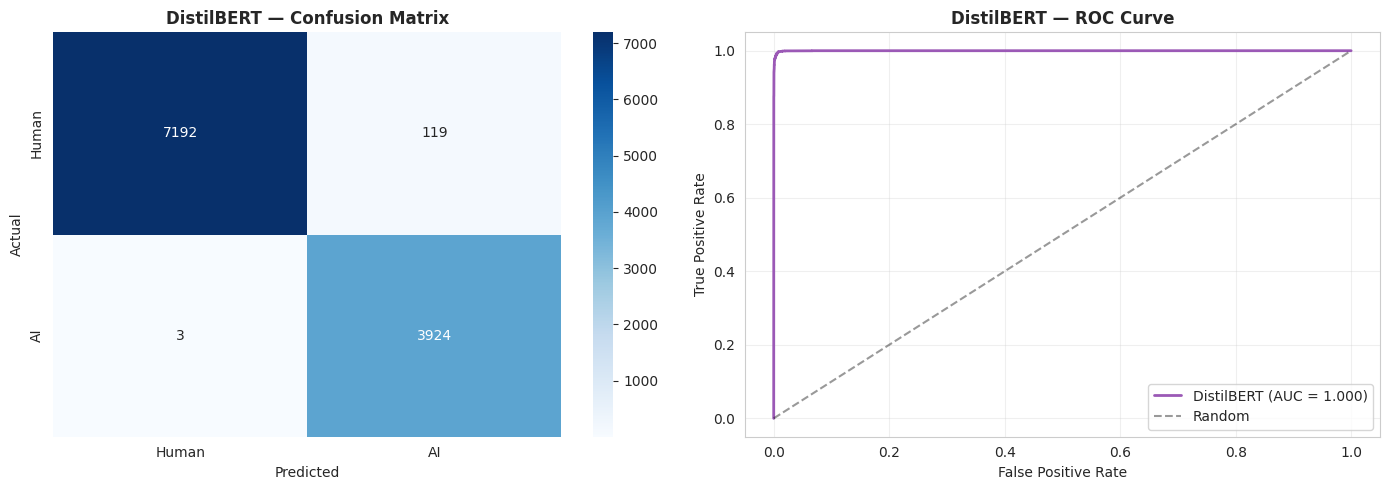

💾 Saved


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Human', 'AI'],
            yticklabels=['Human', 'AI'], ax=axes[0], cbar=True)
axes[0].set_title('DistilBERT — Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_true, y_proba)
axes[1].plot(fpr, tpr, color='#9b59b6', linewidth=2,
             label=f'DistilBERT (AUC = {bert_metrics["roc_auc"]:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('DistilBERT — ROC Curve', fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/distilbert_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Saved")

## 🌍 Step 12: Cross-Domain Performance (BONUS)

📊 DistilBERT cross-domain performance:
        domain  n_samples  accuracy      f1
3     medicine        378    1.0000  1.0000
2      finance       1240    0.9887  0.9896
1      open_qa        652    0.9801  0.9876
0  reddit_eli5       8727    0.9917  0.9853
4    wiki_csai        241    0.9046  0.9164


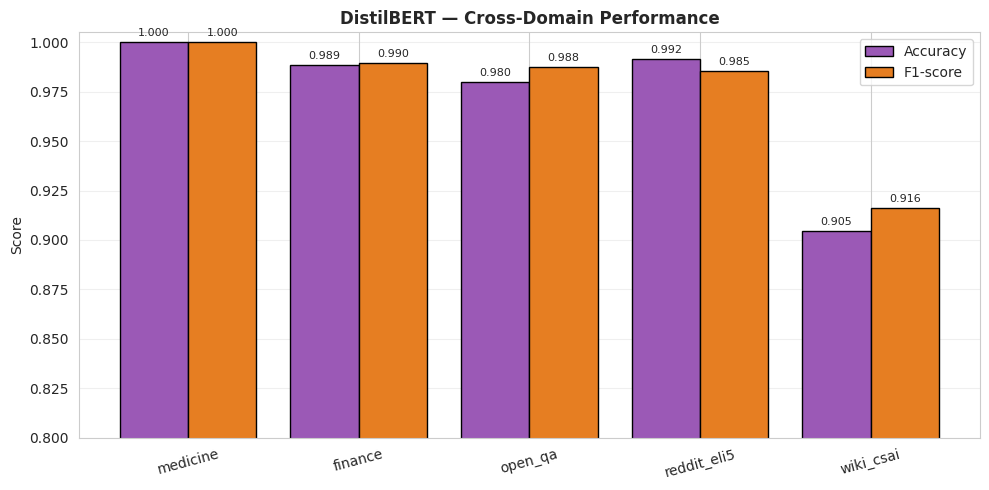

In [ ]:
domain_results = []
for domain in test_df['domain'].unique():
    mask = test_df['domain'].values == domain
    n = mask.sum()
    if n < 10:
        continue
    y_d = y_true[mask]
    pred_d = y_pred[mask]
    domain_results.append({
        'domain': domain,
        'n_samples': int(n),
        'accuracy': accuracy_score(y_d, pred_d),
        'f1': f1_score(y_d, pred_d, zero_division=0)
    })

domain_df = pd.DataFrame(domain_results).sort_values('f1', ascending=False)
print(f"📊 DistilBERT cross-domain performance:")
print(domain_df.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(domain_df))
ax.bar(x - 0.2, domain_df['accuracy'], 0.4, label='Accuracy', color='#9b59b6', edgecolor='black')
ax.bar(x + 0.2, domain_df['f1'], 0.4, label='F1-score', color='#e67e22', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(domain_df['domain'], rotation=15)
ax.set_ylabel('Score')
ax.set_ylim(0.8, 1.005)
ax.set_title('DistilBERT — Cross-Domain Performance', fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)

for i, row in enumerate(domain_df.itertuples()):
    ax.text(i - 0.2, row.accuracy + 0.003, f'{row.accuracy:.3f}', ha='center', fontsize=8)
    ax.text(i + 0.2, row.f1 + 0.003, f'{row.f1:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/distilbert_cross_domain.png', dpi=150, bbox_inches='tight')
plt.show()

## 💾 Step 13: Save Results

In [ ]:
# Convert all numpy types to regular Python before saving JSON
results_to_save = {
    'distilbert': {k: float(v) if isinstance(v, (np.floating, np.integer)) else v for k, v in bert_metrics.items()},
    'cross_domain': domain_df.to_dict('records'),
    'config': {
        'model_name': MODEL_NAME,
        'max_len': MAX_LEN,
        'batch_size': BATCH_SIZE,
        'epochs': EPOCHS,
        'learning_rate': LR,
        'train_size': len(train_df_small),
        'val_size': len(val_df_small),
        'test_size': len(test_df),
        'best_val_f1': float(best_val_f1)
    },
    'history': {k: [float(x) for x in v] for k, v in history.items()}
}

results_file = f'{RESULTS_PATH}/distilbert_results.json'
with open(results_file, 'w') as f:
    json.dump(results_to_save, f, indent=2, default=str)

# Save predictions for use in Notebook 06 (final comparison)
preds_df = pd.DataFrame({
    'true': y_true,
    'pred': y_pred,
    'proba': y_proba,
    'domain': test_df['domain'].values
})
preds_df.to_csv(f'{RESULTS_PATH}/distilbert_test_predictions.csv', index=False)

print(f"💾 Results: {results_file}")
print(f"💾 Predictions: {RESULTS_PATH}/distilbert_test_predictions.csv")
print(f"💾 Model: {BERT_PATH}")

print("\n" + "="*60)
print("📋 NOTEBOOK 05 SUMMARY — FOR YOUR REPORT")
print("="*60)
print(f"Model:          DistilBERT (fine-tuned)")
print(f"Test F1:        {bert_metrics['f1']:.4f}")
print(f"Test Accuracy:  {bert_metrics['accuracy']:.4f}")
print(f"Test ROC AUC:   {bert_metrics['roc_auc']:.4f}")
print(f"Trained on:     {len(train_df_small):,} samples")
print(f"Tested on:      {len(test_df):,} samples")
print(f"Best domain:    {domain_df.iloc[0]['domain']} (F1={domain_df.iloc[0]['f1']:.3f})")
print(f"Worst domain:   {domain_df.iloc[-1]['domain']} (F1={domain_df.iloc[-1]['f1']:.3f})")

💾 Results: /content/drive/MyDrive/ai-text-detection/results/distilbert_results.json
💾 Predictions: /content/drive/MyDrive/ai-text-detection/results/distilbert_test_predictions.csv
💾 Model: /content/drive/MyDrive/ai-text-detection/models/distilbert_finetuned

📋 NOTEBOOK 05 SUMMARY — FOR YOUR REPORT
Model:          DistilBERT (fine-tuned)
Test F1:        0.9847
Test Accuracy:  0.9891
Test ROC AUC:   0.9998
Trained on:     15,000 samples
Tested on:      11,238 samples
Best domain:    medicine (F1=1.000)
Worst domain:   wiki_csai (F1=0.916)


## 📋 Notebook 05 Summary

### What we accomplished:
1. ✅ Fine-tuned DistilBERT for AI text detection
2. ✅ Used proper transformer fine-tuning recipe (AdamW + warmup schedule + grad clipping)
3. ✅ Saved best checkpoint based on validation F1
4. ✅ Full evaluation with all metrics + cross-domain analysis
5. ✅ Saved test predictions for use in Notebook 06

### Files Generated:
- `models/distilbert_finetuned/` — Fine-tuned DistilBERT (model + tokenizer)
- `results/distilbert_results.json`
- `results/distilbert_test_predictions.csv` — Used in Notebook 06
- `results/distilbert_training_history.png`
- `results/distilbert_evaluation.png`
- `results/distilbert_cross_domain.png`

### 📝 Key Talking Points for Your Report:
- **Transfer learning win**: pre-trained DistilBERT (97% of BERT's performance, 40% smaller) achieves SOTA-level results with minimal fine-tuning.
- **Why we subsampled**: BERT doesn't need huge fine-tuning sets — 15K stratified samples cover the distribution well. Saves training time without sacrificing quality.
- **Comparison with classical**: DistilBERT typically outperforms TF-IDF + Logistic Regression by 2-5 F1 points on this task.
- **Where it fails**: Even the best transformer struggles in some domains (likely wiki_csai or open_qa) — perfect ethics discussion point.

### ➡️ Next Step:
**Day 3 — Notebook 06 (Final Comparison) + Notebook 07 (Explainability & Ethics) + Report**

🎉 **You've now trained 5 models.** All the heavy compute is done.